# Validação das copas arbóreas — IoU e F1-score (2024–2026)
**TCC — Engenharia da Computação**. Compara a segmentação **sem correção** e **corrigida** com uma **referência manual independente**. A correspondência entre copas é espacial, não por ID.

**Critério:** IoU ≥ 0,50 e correspondência exclusiva (uma previsão ↔ uma referência). O IoU médio apresentado é calculado **somente entre verdadeiros positivos**. O F1-score contabiliza também as copas não correspondidas.


In [ ]:
%pip -q install geopandas shapely scipy matplotlib pandas pyogrio

## 1. Enviar os nove arquivos GeoPackage
Execute a célula abaixo e selecione **exatamente os nove arquivos**. O notebook não precisa que os IDs sejam iguais.

In [ ]:
from google.colab import files
from pathlib import Path
uploads = files.upload()
print(f"Arquivos recebidos: {len(uploads)}")

Saving 2024.gpkg to 2024.gpkg
Saving 2025.gpkg to 2025 (1).gpkg
Saving 2026.gpkg to 2026 (1).gpkg
Saving segmentacao_manual_2024.gpkg to segmentacao_manual_2024 (1).gpkg
Saving segmentacao_manual_2025.gpkg to segmentacao_manual_2025 (1).gpkg
Saving segmentacao_manual_2026.gpkg to segmentacao_manual_2026 (1).gpkg
Saving sem_correcao_2024.gpkg to sem_correcao_2024 (1).gpkg
Saving sem_correcao_2025.gpkg to sem_correcao_2025 (1).gpkg
Saving sem_correcao_2026.gpkg to sem_correcao_2026 (1).gpkg
Arquivos recebidos: 9


## 2. Definir nomes de entrada
Se você renomeou algum arquivo, altere somente os nomes no dicionário abaixo. As versões `2024.gpkg`, `2025.gpkg` e `2026.gpkg` são as **corrigidas**.

In [ ]:
ARQUIVOS = {
  2024: {'manual': 'segmentacao_manual_2024.gpkg', 'original': 'sem_correcao_2024.gpkg', 'corrigida': '2024.gpkg'},
  2025: {'manual': 'segmentacao_manual_2025.gpkg', 'original': 'sem_correcao_2025.gpkg', 'corrigida': '2025.gpkg'},
  2026: {'manual': 'segmentacao_manual_2026.gpkg', 'original': 'sem_correcao_2026.gpkg', 'corrigida': '2026.gpkg'},
}
for ano, grupos in ARQUIVOS.items():
    for tipo, nome in grupos.items():
        if not Path(nome).is_file():
            raise FileNotFoundError(f'Falta {ano}/{tipo}: {nome}. Verifique o nome enviado.')
print('Os nove arquivos foram encontrados.')

Os nove arquivos foram encontrados.


## 3. Conferir geometrias e sistemas de coordenadas
O EPSG:31980 usa metros. A verificação de extensão detecta arquivos que **declaram** EPSG:31980, mas guardam números em graus. O código **interrompe** a análise se encontrar esse problema; não altera o SRC silenciosamente.

In [ ]:
import geopandas as gpd
import numpy as np
import pandas as pd
from scipy.optimize import linear_sum_assignment
import matplotlib.pyplot as plt

EPSG_ANALISE = 'EPSG:31980'
LIMIAR_IOU = 0.50

def carregar(nome):
    gdf = gpd.read_file(nome)
    if gdf.crs is None:
        raise ValueError(f'{nome}: SRC ausente. Verifique no QGIS antes de continuar.')
    if gdf.empty:
        raise ValueError(f'{nome}: camada vazia.')
    if gdf.geometry.isna().any() or gdf.geometry.is_empty.any():
        raise ValueError(f'{nome}: contém geometrias nulas ou vazias.')
    if not gdf.geometry.is_valid.all():
        raise ValueError(f'{nome}: contém geometrias inválidas. Corrija no QGIS.')
    if str(gdf.crs).upper() == EPSG_ANALISE:
        xmin, ymin, xmax, ymax = gdf.total_bounds
        if max(abs(xmin), abs(xmax)) <= 180 and max(abs(ymin), abs(ymax)) <= 90:
            raise ValueError(f'{nome}: declarado EPSG:31980, mas coordenadas parecem graus! Reprojete corretamente no QGIS.')
    gdf = gdf.to_crs(EPSG_ANALISE)
    if not gdf.geometry.geom_type.isin(['Polygon', 'MultiPolygon']).all():
        raise ValueError(f'{nome}: há geometrias que não são polígonos.')
    return gdf.reset_index(drop=True)

CAMADAS = {}
for ano, grupos in ARQUIVOS.items():
    CAMADAS[ano] = {}
    for tipo, nome in grupos.items():
        gdf = carregar(nome)
        CAMADAS[ano][tipo] = gdf
        print(f'{ano} | {tipo:9} | {len(gdf):2} polígonos | {gdf.crs} | área total {gdf.geometry.area.sum():.2f} m²')

## 4. Calcular IoU e correspondências individuais
A matriz guarda o IoU entre **cada** polígono da IA e **cada** polígono manual. A associação usa otimização bipartida com possibilidade de deixar polígonos sem par, priorizando o número de correspondências acima do limiar e depois o IoU total. Nenhuma copa é associada duas vezes.

In [ ]:
def matriz_iou(previstos, referencia):
    matriz = np.zeros((len(previstos), len(referencia)), dtype=float)
    for i, geom_ia in enumerate(previstos.geometry):
        for j, geom_ref in enumerate(referencia.geometry):
            intersecao = geom_ia.intersection(geom_ref).area
            if intersecao <= 0:
                continue
            uniao = geom_ia.union(geom_ref).area
            matriz[i, j] = intersecao / uniao if uniao else 0.0
    return matriz

def avaliar(previstos, referencia, ano, versao, limiar=LIMIAR_IOU):
    M = matriz_iou(previstos, referencia)
    n, m = M.shape
    # Matriz ampliada com pares fictícios: permite FP e FN sem forçar associações ruins.
    # Cada correspondência válida recebe peso grande, depois seu IoU decide desempates.
    pesos = np.zeros((n+m, n+m))
    pesos[:n, :m] = np.where(M >= limiar, 2.0 + M, -1.0)
    linhas, colunas = linear_sum_assignment(pesos, maximize=True)
    pares = [(int(i), int(j), float(M[i,j])) for i,j in zip(linhas, colunas)
             if i < n and j < m and M[i,j] >= limiar]
    ids_ia = {i for i,j,v in pares}
    ids_ref = {j for i,j,v in pares}
    vp = len(pares); fp = n-vp; fn = m-vp
    precisao = vp/(vp+fp) if vp+fp else 0.0
    recall = vp/(vp+fn) if vp+fn else 0.0
    f1 = 2*precisao*recall/(precisao+recall) if precisao+recall else 0.0
    resultado = {'ano': ano, 'versao': versao, 'n_ia': n, 'n_manual': m,
                 'VP': vp, 'FP': fp, 'FN': fn, 'precision': precisao,
                 'recall': recall, 'f1_score': f1,
                 'iou_medio_VP': np.mean([v for _,_,v in pares]) if pares else np.nan,
                 'limiar_iou': limiar}
    detalhes = []
    for i,j,v in pares:
        detalhes.append({'ano':ano,'versao':versao,'status':'VP','indice_ia':i+1,'indice_manual':j+1,'iou':v})
    for i in range(n):
        if i not in ids_ia:
            detalhes.append({'ano':ano,'versao':versao,'status':'FP','indice_ia':i+1,'indice_manual':None,'iou':None})
    for j in range(m):
        if j not in ids_ref:
            detalhes.append({'ano':ano,'versao':versao,'status':'FN','indice_ia':None,'indice_manual':j+1,'iou':None})
    return resultado, detalhes, M

resultados, correspondencias, MATRIZES = [], [], {}
for ano in sorted(CAMADAS):
    for tipo, rotulo in [('original','IA original'),('corrigida','IA corrigida')]:
        res, det, mat = avaliar(CAMADAS[ano][tipo], CAMADAS[ano]['manual'], ano, rotulo)
        resultados.append(res)
        correspondencias.extend(det)
        MATRIZES[(ano, rotulo)] = mat

resumo = pd.DataFrame(resultados)
detalhes = pd.DataFrame(correspondencias)
display(resumo.round(4))

,ano,versao,n_ia,n_manual,VP,FP,FN,precision,recall,f1_score,iou_medio_VP,limiar_iou
0,2024,IA original,18,18,15,3,3,0.8333,0.8333,0.8333,0.7071,0.5
1,2024,IA corrigida,18,18,18,0,0,1.0000,1.0000,1.0000,0.8250,0.5
2,2025,IA original,17,18,16,1,2,0.9412,0.8889,0.9143,0.8092,0.5
3,2025,IA corrigida,18,18,18,0,0,1.0000,1.0000,1.0000,0.8687,0.5
4,2026,IA original,18,18,16,2,2,0.8889,0.8889,0.8889,0.8522,0.5
5,2026,IA corrigida,18,18,18,0,0,1.0000,1.0000,1.0000,0.8804,0.5


## 5. Gráficos de comparação
F1-score mede a identificação segundo o limiar escolhido; IoU médio mede a coincidência espacial **dos pares aceitos**. F1=1 não implica IoU=1.

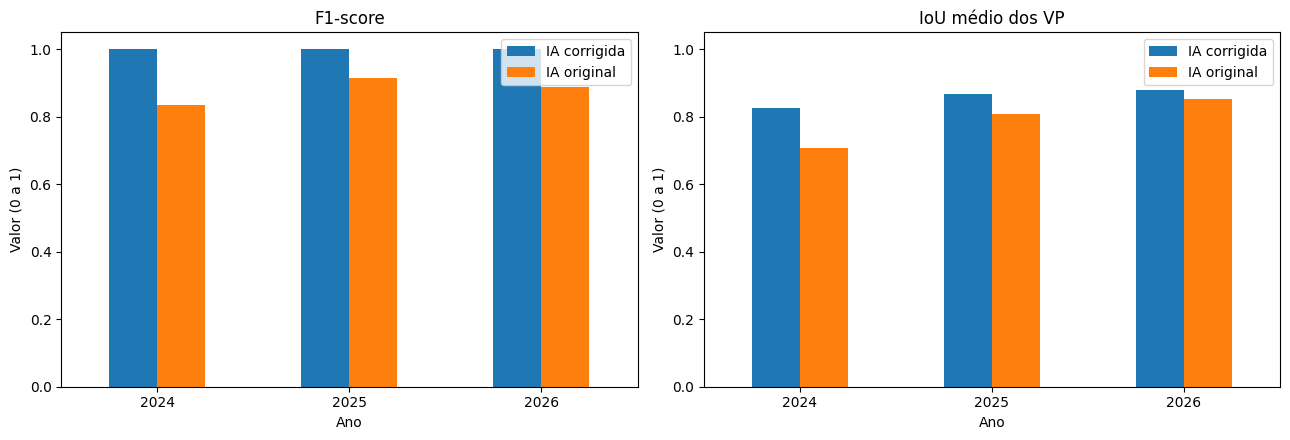

In [ ]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, coluna, titulo in zip(eixos, ['f1_score','iou_medio_VP'], ['F1-score', 'IoU médio dos VP']):
    tabela = resumo.pivot(index='ano', columns='versao', values=coluna)
    tabela.plot(kind='bar', ax=ax)
    ax.set_title(titulo)
    ax.set_ylim(0,1.05)
    ax.set_ylabel('Valor (0 a 1)')
    ax.set_xlabel('Ano')
    ax.tick_params(axis='x', rotation=0)
    ax.legend(title='')
plt.tight_layout()
plt.savefig('grafico_validacao_segmentacao.png', dpi=200, bbox_inches='tight')
plt.show()

## 6. Inspeção visual das correspondências
Mostra o contorno da referência manual e da versão selecionada sobre o mesmo espaço. Consulte `detalhes` para localizar VP, FP e FN. Índices exibidos são **posições sequenciais**, não IDs originais.

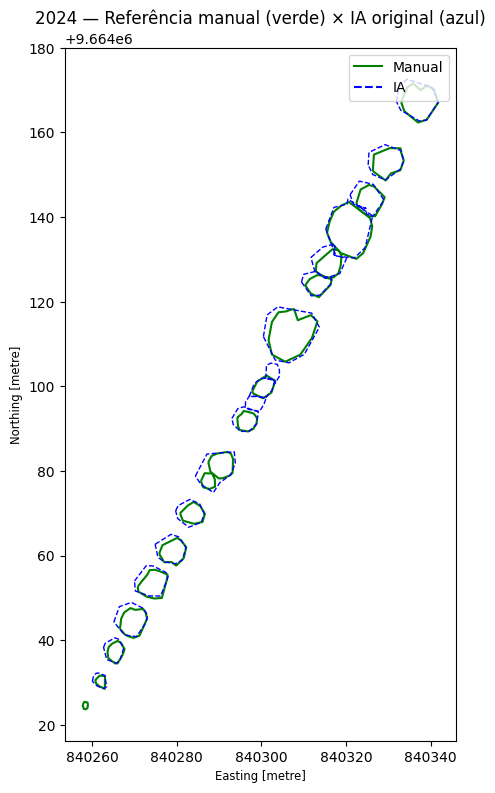

,ano,versao,status,indice_ia,indice_manual,iou
0,2024,IA original,VP,2.0,15.0,0.855295
1,2024,IA original,VP,3.0,14.0,0.610163
2,2024,IA original,VP,4.0,18.0,0.768322
3,2024,IA original,VP,5.0,17.0,0.759537
4,2024,IA original,VP,6.0,16.0,0.685263
5,2024,IA original,VP,7.0,4.0,0.690862
6,2024,IA original,VP,8.0,5.0,0.694292
7,2024,IA original,VP,9.0,7.0,0.649418
8,2024,IA original,VP,10.0,10.0,0.622578
9,2024,IA original,VP,11.0,3.0,0.679586


In [ ]:
ANO = 2024
VERSAO = 'original'  # 'original' ou 'corrigida'
fig, ax = plt.subplots(figsize=(8, 9))
CAMADAS[ANO]['manual'].boundary.plot(ax=ax, color='green', linewidth=1.5, label='Manual')
CAMADAS[ANO][VERSAO].boundary.plot(ax=ax, color='blue', linewidth=1, linestyle='--', label='IA')
ax.set_title(f'{ANO} — Referência manual (verde) × IA {VERSAO} (azul)')
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([0],[0],color='green',label='Manual'),Line2D([0],[0],color='blue',linestyle='--',label='IA')])
ax.set_aspect('equal')
plt.show()
display(detalhes[(detalhes.ano == ANO) & (detalhes.versao == ('IA original' if VERSAO=='original' else 'IA corrigida'))])

## 7. Exportar resultados para o dashboard e para o TCC

In [ ]:
resumo.to_csv('validacao_segmentacao_resultados.csv', index=False, encoding='utf-8-sig')
detalhes.to_csv('validacao_segmentacao_correspondencias.csv', index=False, encoding='utf-8-sig')
for nome in ['validacao_segmentacao_resultados.csv', 'validacao_segmentacao_correspondencias.csv', 'grafico_validacao_segmentacao.png']:
    files.download(nome)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Observações metodológicas para a banca
- **IoU** = área de interseção / área de união de duas copas.
- **VP** = previsão associada exclusivamente a uma copa de referência com IoU ≥ 0,50; **FP** = previsão não associada; **FN** = copa de referência não associada.
- **Precision** = VP/(VP+FP); **Recall** = VP/(VP+FN); **F1** = 2·Precision·Recall/(Precision+Recall).
- O limiar 0,50 deve ser declarado e justificado. Se necessário, teste também 0,25 e 0,75 como análise de sensibilidade da avaliação.
- A referência manual precisa ser produzida **independentemente** da segmentação automática para sustentar uma validação independente.
- As imagens do Google Earth têm limitações de resolução, sombras e sobreposição de copas; os resultados não constituem validação de biomassa observada em campo.
- Verifique visualmente as associações, especialmente árvores com copas unidas ou divididas entre anos.